## Data Loading

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [15]:
import pandas as pd

df = pd.read_csv(r"C:\Users\hp\Downloads\all_upwork_jobs_2024-02-07-2024-03-24 (1).csv")
df["published_date"] = pd.to_datetime(df["published_date"], errors="coerce")
df["avg_hourly"] = df[["hourly_low", "hourly_high"]].mean(axis=1)

print(df.head())

                                               title  \
0  Experienced Media Buyer For Solar Pannel and R...   
1                               Full Stack Developer   
2                                    SMMA Bubble App   
3             Talent Hunter Specialized in Marketing   
4                                      Data Engineer   

                                                link  \
0  https://www.upwork.com/jobs/Experienced-Media-...   
1  https://www.upwork.com/jobs/Full-Stack-Develop...   
2  https://www.upwork.com/jobs/SMMA-Bubble-App_%7...   
3  https://www.upwork.com/jobs/Talent-Hunter-Spec...   
4  https://www.upwork.com/jobs/Data-Engineer_%7E0...   

             published_date  is_hourly  hourly_low  hourly_high  budget  \
0 2024-02-17 09:09:54+00:00      False         NaN          NaN   500.0   
1 2024-02-17 09:09:17+00:00      False         NaN          NaN  1100.0   
2 2024-02-17 09:08:46+00:00       True        10.0         30.0     NaN   
3 2024-02-17 09:08:08+00:0

In [16]:
df.head()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country,avg_hourly
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States,NaN
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States,20.0
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States,NaN
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India,NaN


In [17]:
df.shape

(244828, 9)

In [18]:
df.isnull()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country,avg_hourly
0,False,False,False,False,True,True,False,True,True
1,False,False,False,False,True,True,False,False,True
2,False,False,False,False,False,False,True,False,False
3,False,False,False,False,True,True,True,False,True
4,False,False,False,False,True,True,False,False,True
...,...,...,...,...,...,...,...,...,...
244823,False,False,False,False,False,False,True,False,False
244824,False,False,False,False,True,True,False,False,True
244825,False,False,False,False,False,False,True,False,False
244826,False,False,False,False,True,True,False,False,True


In [19]:
 df.drop


<bound method DataFrame.drop of                                                     title  \
0       Experienced Media Buyer For Solar Pannel and R...   
1                                    Full Stack Developer   
2                                         SMMA Bubble App   
3                  Talent Hunter Specialized in Marketing   
4                                           Data Engineer   
...                                                   ...   
244823  Need Facebook advertising experts to launch pr...   
244824          Digital/Telemarketing/Sales/OutSide Sales   
244825                           WordPress Template Edits   
244826            ELEMENTOR PRO For quick fix (Wordpress)   
244827              Creating a UGC Ad for Our Mobile Game   

                                                     link  \
0       https://www.upwork.com/jobs/Experienced-Media-...   
1       https://www.upwork.com/jobs/Full-Stack-Develop...   
2       https://www.upwork.com/jobs/SMMA-Bubble-App_

## Keyword Salaries Analysis

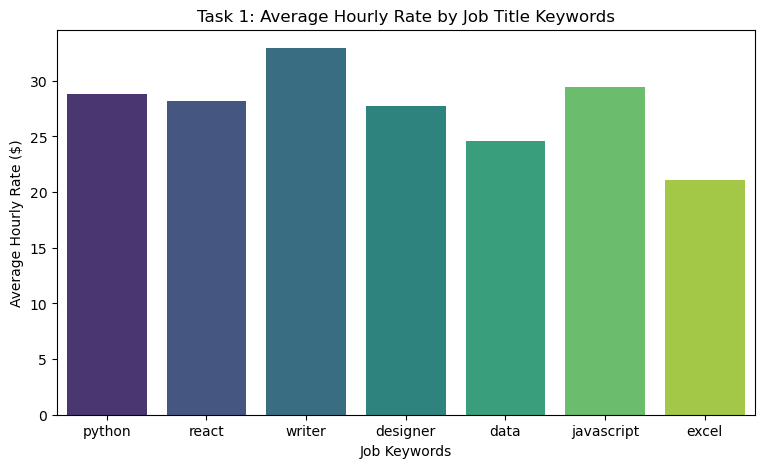

In [20]:
keywords = ['python', 'react', 'writer', 'designer', 'data', 'javascript', 'excel']
keyword_salaries = {
    kw: df[df["title"].str.contains(kw, case=False, na=False)]["avg_hourly"].mean()
    for kw in keywords
}

# Chart
plt.figure(figsize=(9, 5))
sns.barplot(x=list(keyword_salaries.keys()), y=list(keyword_salaries.values()), palette="viridis", hue=list(keyword_salaries.keys()), legend=False)
plt.title("Task 1: Average Hourly Rate by Job Title Keywords")
plt.xlabel("Job Keywords")
plt.ylabel("Average Hourly Rate ($)")
plt.savefig("task1_keyword_salaries.png", bbox_inches="tight")
plt.show()

In [21]:
print("Task 1 - Average Hourly Rate by Keyword:")
for kw, sal in keyword_salaries.items():
  print(f"- {kw}: ${sal:.2f}")

Task 1 - Average Hourly Rate by Keyword:
- python: $28.81
- react: $28.17
- writer: $32.94
- designer: $27.70
- data: $24.59
- javascript: $29.41
- excel: $21.07


## Job Categories & Rate Distribution

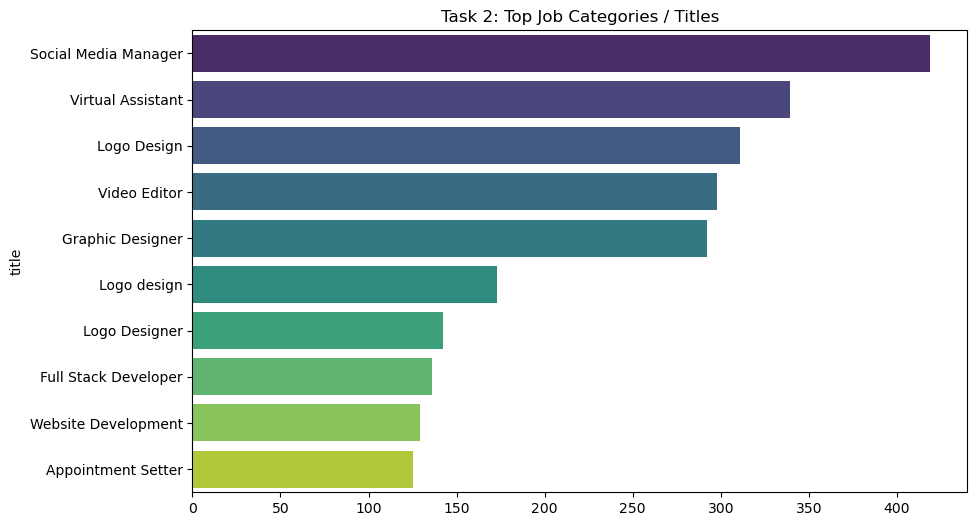

In [22]:
# Top Categories
cat_cols = [col for col in df.columns if 'category' in col.lower() or 'title' in col.lower()]
if cat_cols:
    top_cats = df[cat_cols[0]].value_counts().head(10)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=top_cats.values, y=top_cats.index, palette="viridis", hue=top_cats.index, legend=False)
    plt.title("Task 2: Top Job Categories / Titles")
    plt.savefig("task2_top_categories.png", bbox_inches="tight")
    plt.show()

## Country-wise Hourly Rates Comparison

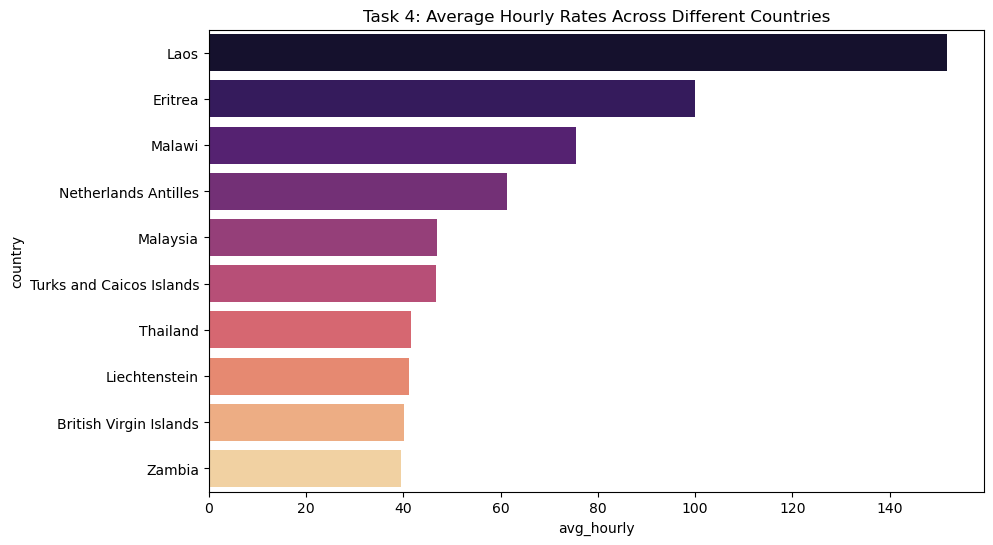

In [23]:
country_cols = [col for col in df.columns if 'country' in col.lower()]
if country_cols:
    country_rates = df.groupby(country_cols[0])['avg_hourly'].mean().reset_index()
    country_rates = country_rates.dropna().sort_values(by='avg_hourly', ascending=False).head(10)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x='avg_hourly', y=country_cols[0], data=country_rates, palette="magma", hue=country_cols[0], legend=False)
    plt.title("Task 4: Average Hourly Rates Across Different Countries")
    plt.savefig("task4_country_hourly_rates.png", bbox_inches="tight")
    plt.show()

## Job Recommendation Engine

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

rec_df = df.dropna(subset=["title"]).head(3000).copy()
tfidf = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf.fit_transform(rec_df["title"])

user_query = ["Python Backend Developer"]
user_vec = tfidf.transform(user_query)
similarity = cosine_similarity(user_vec, tfidf_matrix).flatten()
top_idx = similarity.argsort()[-3:][::-1]

print(f"Task 5 - Recommendations for query: '{user_query[0]}'")
for idx in top_idx:
  print(f"- {rec_df.iloc[idx]['title']} ({rec_df.iloc[idx]['link']})")

Task 5 - Recommendations for query: 'Python Backend Developer'
- BackEnd Developer (https://www.upwork.com/jobs/BackEnd-Developer_%7E01afd9ada69a4e0f6e?source=rss)
- BackEnd Developer (https://www.upwork.com/jobs/BackEnd-Developer_%7E013ff2bb8c2e9deb2e?source=rss)
- Website Backend Developer (https://www.upwork.com/jobs/Website-Backend-Developer_%7E01a3de534b3155458c?source=rss)


## Track Changes in Job Market Dynamics Over Months

Task 6 - Monthly Job Market Dynamics:
  year_month  job_count
0    2023-11          1
1    2023-12         10
2    2024-01         96
3    2024-02     101887
4    2024-03     142834


C:\Users\hp\AppData\Local\Temp\ipykernel_17116\2039794857.py:17: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['year_month'] = df[date_col].dt.to_period('M')


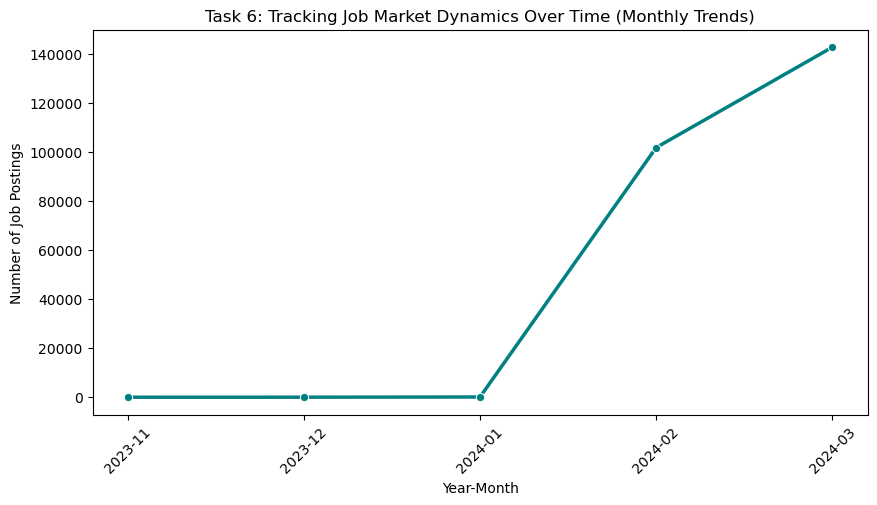

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure dataset is loaded
if 'df' not in locals():
    df = pd.read_csv(r"C:\Users\hp\Desktop\job anlysis\all_upwork_jobs_2024-02-07-2024-03-24.csv")

# 2. Find the date column and convert it to datetime
date_cols = [col for col in df.columns if 'date' in col.lower() or 'time' in col.lower()]

if date_cols:
    date_col = date_cols[0]
    df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
    
    # Extract Year-Month to track monthly dynamics
    df['year_month'] = df[date_col].dt.to_period('M')
    monthly_trends = df.groupby('year_month').size().reset_index(name='job_count')
    monthly_trends['year_month'] = monthly_trends['year_month'].astype(str)
    
    print("Task 6 - Monthly Job Market Dynamics:")
    print(monthly_trends)

    # 3. Generate and save the trend chart
    plt.figure(figsize=(10, 5))
    sns.lineplot(
        x='year_month', 
        y='job_count', 
        data=monthly_trends, 
        marker='o', 
        color='teal', 
        linewidth=2.5
    )
    plt.title("Task 6: Tracking Job Market Dynamics Over Time (Monthly Trends)")
    plt.xlabel("Year-Month")
    plt.ylabel("Number of Job Postings")
    plt.xticks(rotation=45)
    plt.savefig("task6_monthly_dynamics.png", bbox_inches="tight")
    plt.show()
else:
    print("No date column found in the dataset for monthly tracking.")

## Investigate Trends in the Remote Work Landscape

Remote Jobs: 5707 | Standard/On-site: 239121


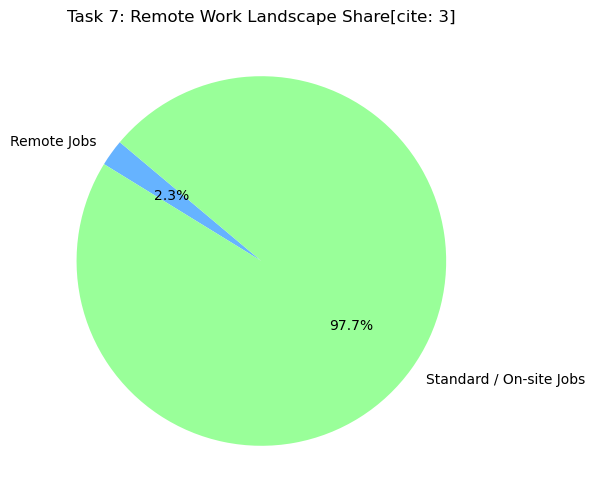

In [26]:
remote_count = df[
    df["title"].str.contains("remote|virtual|work from home", case=False, na=False)
].shape[0]
non_remote_count = len(df) - remote_count

print(f"Remote Jobs: {remote_count} | Standard/On-site: {non_remote_count}")

# Chart 5
plt.figure(figsize=(6, 6))
plt.pie(
    [remote_count, non_remote_count],
    labels=["Remote Jobs", "Standard / On-site Jobs"],
    autopct="%1.1f%%",
    startangle=140,
    colors=["#66b3ff", "#99ff99"],
)
plt.title("Task 7: Remote Work Landscape Share[cite: 3]")
plt.savefig("task7_remote_work_share.png", bbox_inches="tight")
plt.show()

## Predict Future Job Market Trends

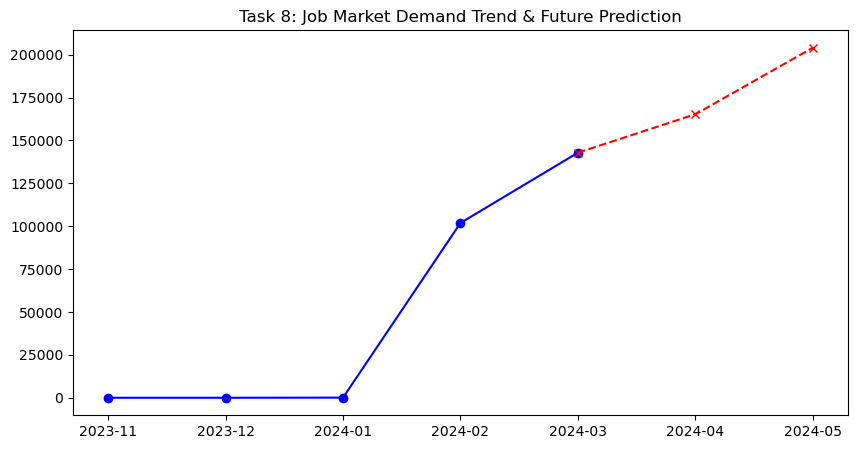

In [27]:
from sklearn.linear_model import LinearRegression

monthly_total = df.groupby('year_month').size().reset_index(name='count')
monthly_total['month_year_str'] = monthly_total['year_month'].astype(str)

X = np.arange(len(monthly_total)).reshape(-1, 1)
y = monthly_total["count"].values
model = LinearRegression().fit(X, y)

future_X = np.arange(len(monthly_total), len(monthly_total) + 2).reshape(-1, 1)
future_preds = model.predict(future_X)
future_months = ["2024-04", "2024-05"]

connect_x = [monthly_total["month_year_str"].iloc[-1]] + future_months
connect_y = [y[-1]] + list(future_preds)

plt.figure(figsize=(10, 5))
plt.plot(monthly_total["month_year_str"], y, marker="o", color="blue", label="Historical Data")
plt.plot(connect_x, connect_y, marker="x", color="red", linestyle="--", label="Predicted Trend")
plt.title("Task 8: Job Market Demand Trend & Future Prediction")
plt.savefig("task3_8_prediction_trend.png", bbox_inches="tight")
plt.show()

In [28]:
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Page configuration
st.set_page_config(page_title="Upwork Jobs Dashboard", page_icon="💼", layout="wide")

# Load data
@st.cache_data
def load_data():
    try:
        df = pd.read_csv('all_upwork_jobs_2024-02-07-2024-03-24.csv')
        return df
    except FileNotFoundError:
        return None

df = load_data()

if df is None:
    st.error("⚠️ CSV file nahi mili! Kripya check karein ki 'all_upwork_jobs_2024-02-07-2024-03-24.csv' file usi folder mein hai.")
else:
    st.title("💼 Upwork Job Market Analysis Dashboard (2024)")
    st.markdown("Explore Upwork job trends, salaries, countries, and keywords interactively.")

    # --- SIDEBAR FILTERS ---
    st.sidebar.header("🔍 Filter Options")

    # 1. Search keyword filter
    search_cols = [col for col in ['title', 'description', 'job_title'] if col in df.columns]
    if search_cols:
        search_keyword = st.sidebar.text_input("Search Job Title/Keywords", "")
        if search_keyword:
            df = df[df[search_cols[0]].str.contains(search_keyword, case=False, na=False)]

    # 2. Country filter
    country_cols = [col for col in df.columns if 'country' in col.lower()]
    if country_cols:
        selected_country = st.sidebar.selectbox("Select Country", ["All"] + list(df[country_cols[0]].dropna().unique()))
        if selected_country != "All":
            df = df[df[country_cols[0]] == selected_country]

    # 3. Rate / Budget Slider Filter
    rate_cols = [col for col in df.columns if 'rate' in col.lower() or 'budget' in col.lower() or 'amount' in col.lower()]
    if rate_cols:
        rate_col = rate_cols[0]
        valid_rates = df[rate_col].dropna()
        if not valid_rates.empty:
            min_val = float(valid_rates.min())
            max_val = float(valid_rates.max())
            if min_val < max_val:
                rate_range = st.sidebar.slider("Select Rate / Budget Range ($)", min_val, max_val, (min_val, max_val))
                df = df[(df[rate_col] >= rate_range[0]) & (df[rate_col] <= rate_range[1])]

    # --- MAIN DASHBOARD METRICS ---
    col1, col2, col3 = st.columns(3)
    col1.metric("Total Jobs Found", len(df))

    if rate_cols:
        avg_rate = df[rate_cols[0]].mean()
        col2.metric("Average Rate / Budget", f"${avg_rate:.2f}" if pd.notnull(avg_rate) else "N/A")
    else:
        col2.metric("Average Rate / Budget", "N/A")

    if country_cols:
        unique_countries = df[country_cols[0]].nunique()
        col3.metric("Active Countries", unique_countries)
    else:
        col3.metric("Active Countries", "N/A")

    st.markdown("---")

    # --- VISUALIZATIONS ---
    st.subheader("📊 Data Visualizations")
    col_a, col_b = st.columns(2)

    with col_a:
        st.markdown("### Top Job Categories / Titles")
        cat_cols = [col for col in df.columns if 'category' in col.lower() or 'title' in col.lower()]
        if cat_cols:
            top_cats = df[cat_cols[0]].value_counts().head(10)
            fig, ax = plt.subplots(figsize=(8, 5))
            sns.barplot(x=top_cats.values, y=top_cats.index, ax=ax, palette="viridis")
            ax.set_xlabel("Job Count")
            ax.set_ylabel("Category / Title")
            st.pyplot(fig)
        else:
            st.info("No category/title column found.")

    with col_b:
        st.markdown("### Rate / Budget Distribution")
        if rate_cols:
            fig, ax = plt.subplots(figsize=(8, 5))
            sns.histplot(df[rate_cols[0]].dropna(), bins=30, kde=True, ax=ax, color="blue")
            ax.set_xlabel("Rate / Budget ($)")
            ax.set_ylabel("Frequency")
            st.pyplot(fig)
        else:
            st.info("No rate/budget column found.")

    # --- DATA PREVIEW ---
    st.subheader("📋 Filtered Data Preview")
    st.dataframe(df.head(50))

2026-10-19 13:06:33.491 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-19 13:06:33.493 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-19 13:06:33.508 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-19 13:06:33.512 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-19 13:06:34.106 
  command:

    streamlit run C:\Users\hp\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-19 13:06:34.108 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-19 13:06:34.109 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in 

In [1]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'
